# Lab Data Preparation — Adult Census Income
**Groupe 4CCE13** · Dataset : Adult (UCI)

Démarche CRISP-DM : Business Understanding → Data Understanding → Exploration → Preparation → Segmentation → Classification → Évaluation

## 1. Business Understanding
- **Contexte** : le dataset Adult est extrait du recensement américain de 1994. Il décrit des individus (âge, éducation, profession, etc.).
- **Problématique de classification** : prédire si une personne gagne plus de 50K$/an (`income`).
- **Problématique de segmentation** : identifier des profils socio-professionnels homogènes (clustering non supervisé).
- **Intérêt** : cibler des politiques publiques ou des offres selon les profils, comprendre les facteurs associés au revenu.

> À compléter avec vos propres mots.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

## 2. Data Understanding

In [2]:
cols = ["age","workclass","fnlwgt","education","education-num","marital-status","occupation",
        "relationship","race","sex","capital-gain","capital-loss","hours-per-week","native-country","income"]

base = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/"
train = pd.read_csv(base+"adult.data", names=cols, skipinitialspace=True)
test  = pd.read_csv(base+"adult.test", names=cols, skipinitialspace=True, skiprows=1)
test["income"] = test["income"].str.rstrip(".")   # le fichier test a un "." en fin de label

df = pd.concat([train, test], ignore_index=True)
print(df.shape)
df.head()

(48842, 15)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


> Si le téléchargement échoue (pas d'internet / URL), télécharge `adult.data` et `adult.test` depuis la page UCI et change `base` par un chemin local.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             48842 non-null  int64
 1   workclass       48842 non-null  str  
 2   fnlwgt          48842 non-null  int64
 3   education       48842 non-null  str  
 4   education-num   48842 non-null  int64
 5   marital-status  48842 non-null  str  
 6   occupation      48842 non-null  str  
 7   relationship    48842 non-null  str  
 8   race            48842 non-null  str  
 9   sex             48842 non-null  str  
 10  capital-gain    48842 non-null  int64
 11  capital-loss    48842 non-null  int64
 12  hours-per-week  48842 non-null  int64
 13  native-country  48842 non-null  str  
 14  income          48842 non-null  str  
dtypes: int64(6), str(9)
memory usage: 5.6 MB


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,48842.0,38.643585,13.710510,17.0,28.0,37.0,48.0,90.0
fnlwgt,48842.0,189664.134597,105604.025423,12285.0,117550.5,178144.5,237642.0,1490400.0
education-num,48842.0,10.078089,2.570973,1.0,9.0,10.0,12.0,16.0
capital-gain,48842.0,1079.067626,7452.019058,0.0,0.0,0.0,0.0,99999.0
capital-loss,48842.0,87.502314,403.004552,0.0,0.0,0.0,0.0,4356.0
hours-per-week,48842.0,40.422382,12.391444,1.0,40.0,40.0,45.0,99.0


In [5]:
# Dictionnaire rapide : types + nb de valeurs uniques
pd.DataFrame({"dtype": df.dtypes, "n_unique": df.nunique(), "exemple": df.iloc[0]})

,dtype,n_unique,exemple
age,int64,74,39
workclass,str,9,State-gov
fnlwgt,int64,28523,77516
education,str,16,Bachelors
education-num,int64,16,13
marital-status,str,7,Never-married
occupation,str,15,Adm-clerical
relationship,str,6,Not-in-family
race,str,5,White
sex,str,2,Male


## 3. Data Exploration

### 3.1 Qualité des données : valeurs manquantes (codées « ? »), doublons

In [6]:
# Les NaN sont codés par "?" dans ce dataset -> pandas ne les voit pas
print("NaN officiels :", df.isna().sum().sum())
missing_q = (df == "?").sum()
missing_q = missing_q[missing_q > 0]
print(missing_q)
print((missing_q / len(df) * 100).round(2).astype(str) + " %")

print("Doublons :", df.duplicated().sum())

NaN officiels : 0
workclass         2799
occupation        2809
native-country     857
dtype: int64
workclass         5.73 %
occupation        5.75 %
native-country    1.75 %
dtype: str
Doublons : 52


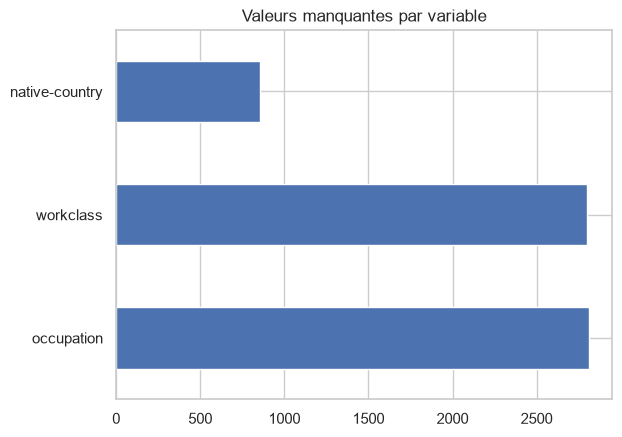

occupation  False  True 
workclass               
False       46033     10
True            0   2799


In [7]:
df = df.replace("?", np.nan)
msno_df = df.isna().sum().sort_values(ascending=False)
msno_df[msno_df > 0].plot(kind="barh", title="Valeurs manquantes par variable")
plt.show()

# Les NaN de workclass et occupation sont-ils liés ?
print(pd.crosstab(df["workclass"].isna(), df["occupation"].isna()))

### 3.2 Variable cible

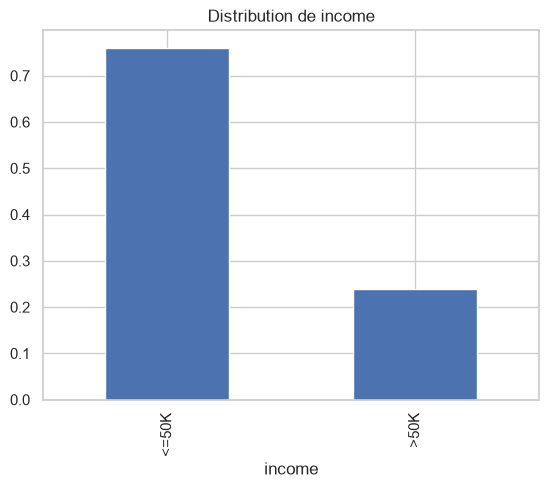

income
<=50K    0.760718
>50K     0.239282
Name: proportion, dtype: float64

In [8]:
df["income"].value_counts(normalize=True).plot(kind="bar", title="Distribution de income")
plt.show()
df["income"].value_counts(normalize=True)

### 3.3 Analyse univariée

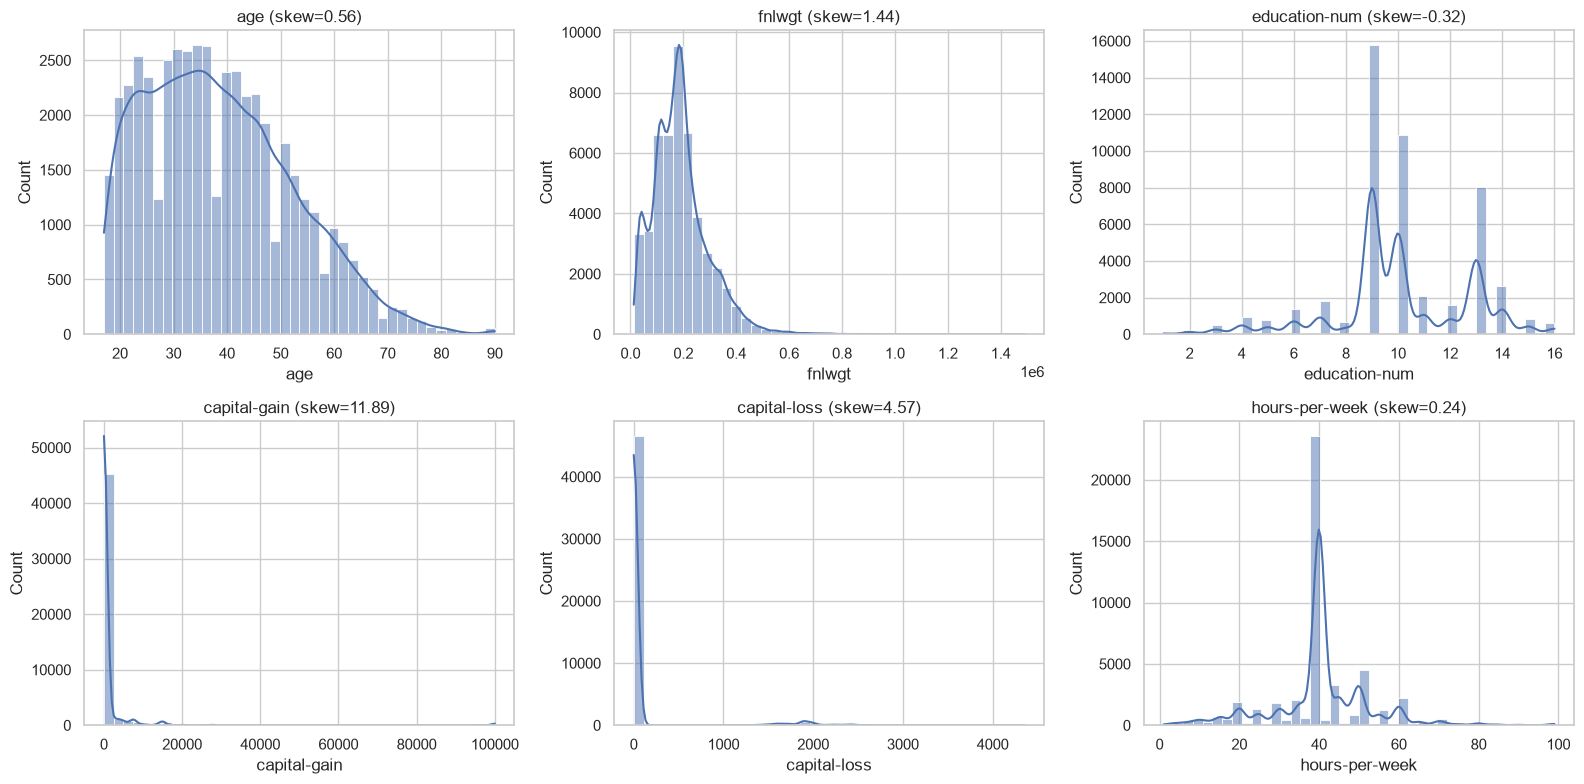

In [9]:
num_cols = ["age","fnlwgt","education-num","capital-gain","capital-loss","hours-per-week"]
cat_cols = [c for c in df.columns if c not in num_cols + ["income"]]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, c in zip(axes.ravel(), num_cols):
    sns.histplot(df[c], bins=40, kde=True, ax=ax)
    ax.set_title(f"{c} (skew={df[c].skew():.2f})")
plt.tight_layout(); plt.show()

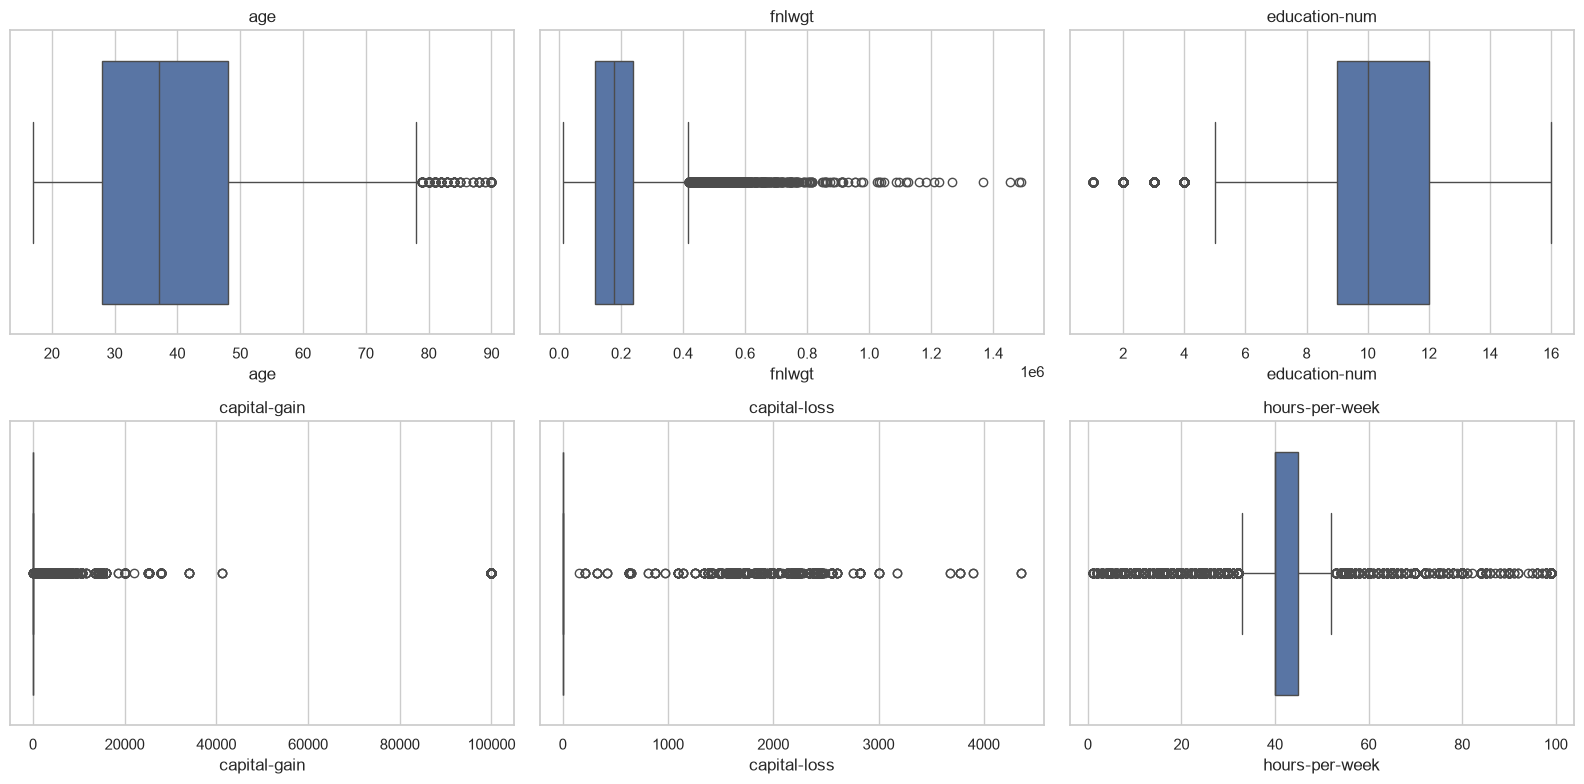

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, c in zip(axes.ravel(), num_cols):
    sns.boxplot(x=df[c], ax=ax)
    ax.set_title(c)
plt.tight_layout(); plt.show()

In [11]:
# capital-gain / capital-loss : beaucoup de zéros ?
for c in ["capital-gain","capital-loss"]:
    print(c, "-> % de zéros :", round((df[c]==0).mean()*100, 1), "| valeurs max :", df[c].max())
print("capital-gain == 99999 :", (df["capital-gain"]==99999).sum(), "lignes (valeur suspecte / plafonnée)")

capital-gain -> % de zéros : 91.7 | valeurs max : 99999
capital-loss -> % de zéros : 95.3 | valeurs max : 4356
capital-gain == 99999 : 244 lignes (valeur suspecte / plafonnée)


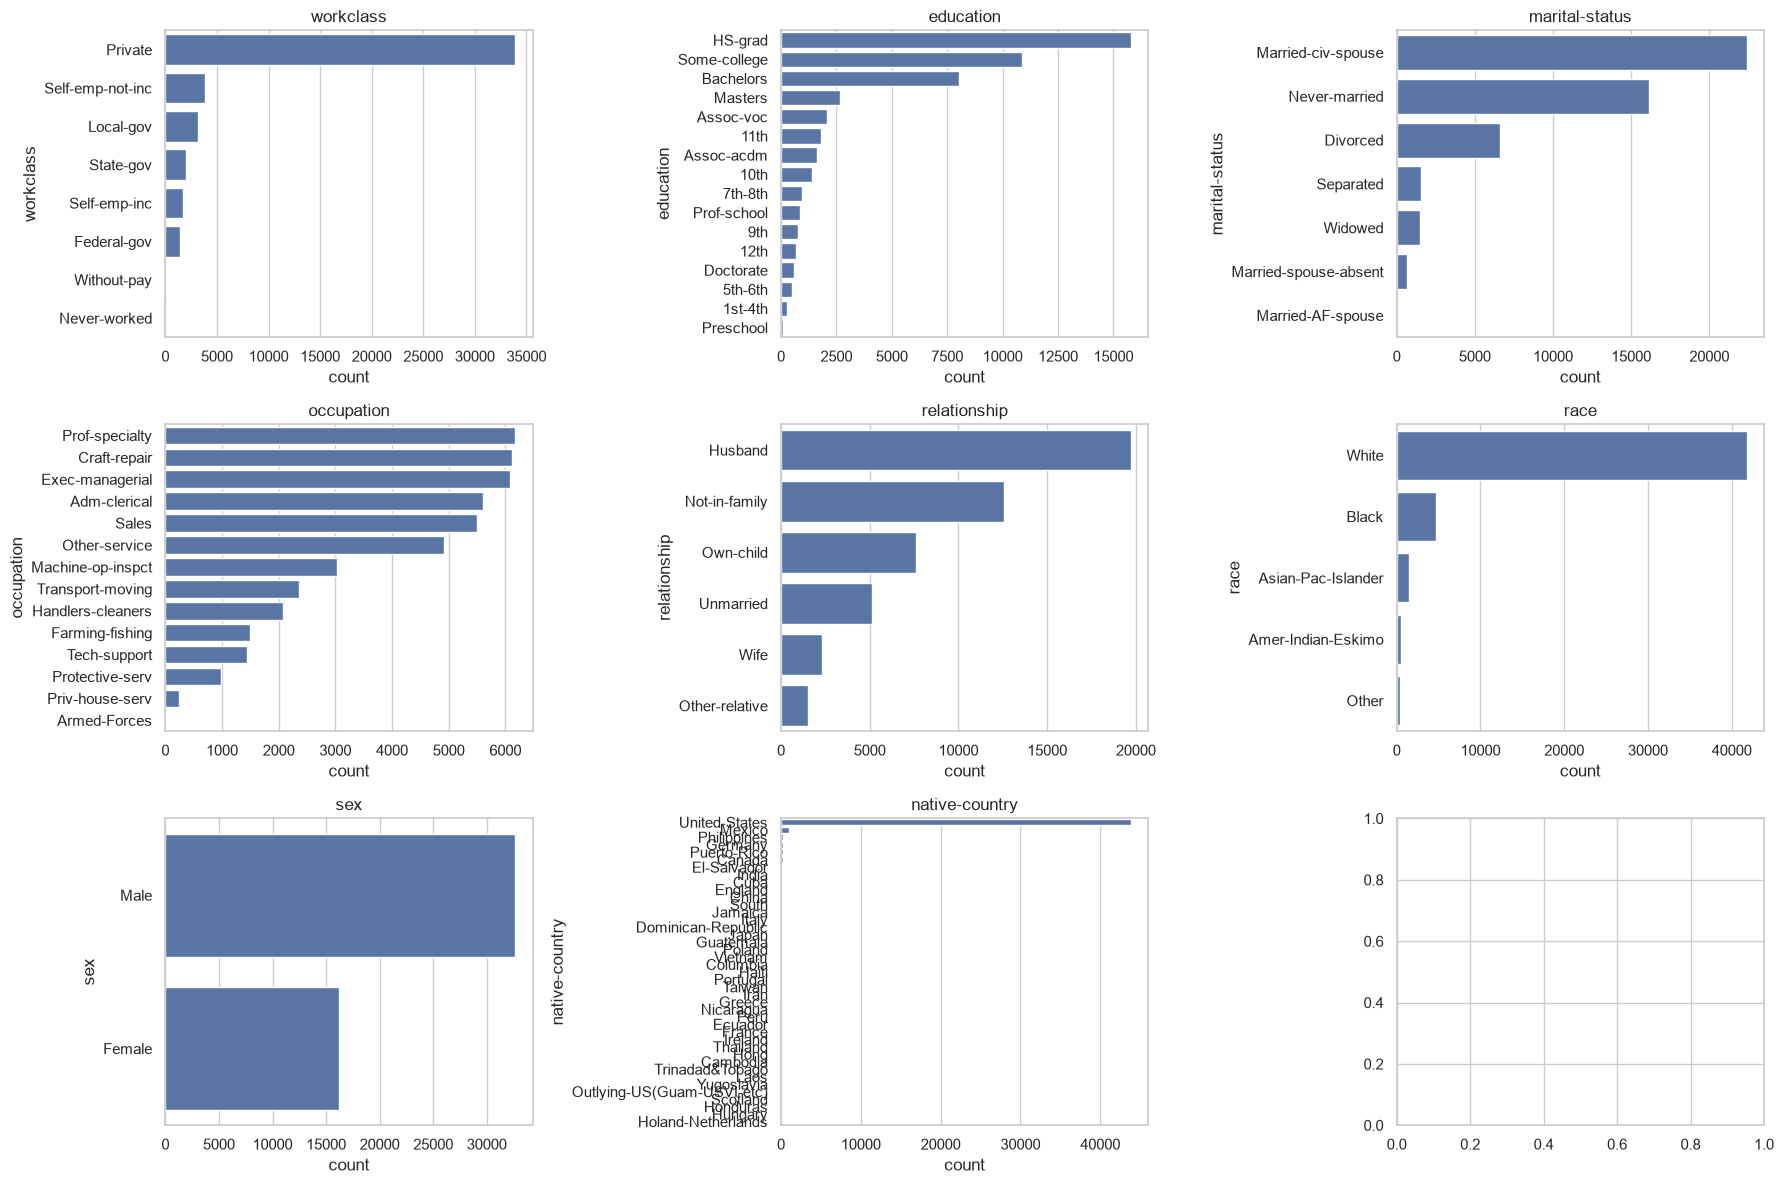

In [12]:
fig, axes = plt.subplots(3, 3, figsize=(18, 12))
for ax, c in zip(axes.ravel(), cat_cols):
    order = df[c].value_counts().index
    sns.countplot(y=df[c], order=order, ax=ax)
    ax.set_title(c)
plt.tight_layout(); plt.show()

### 3.4 Analyse bivariée (relation avec le revenu)

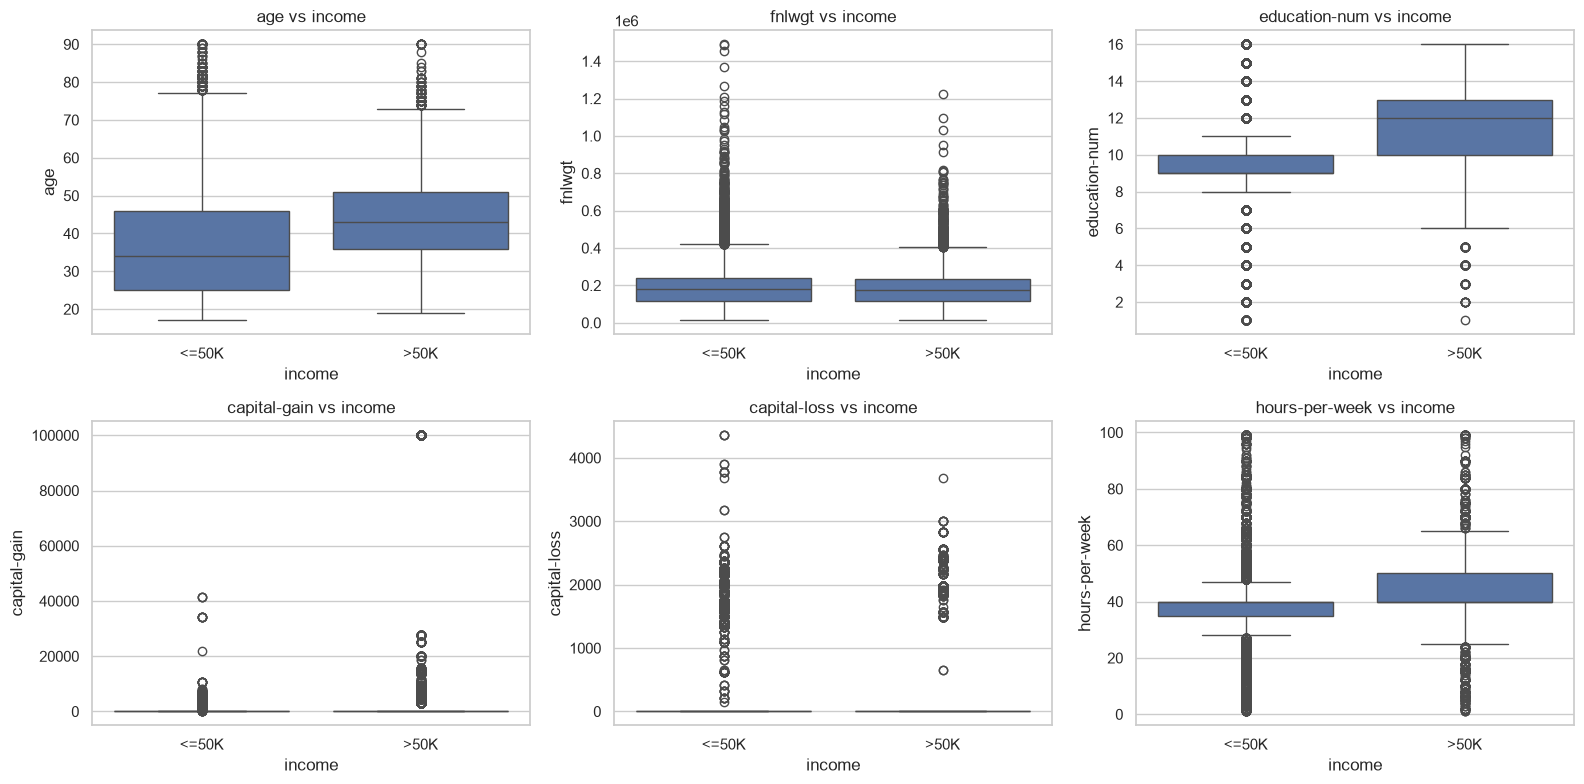

In [13]:
df["target"] = (df["income"] == ">50K").astype(int)

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, c in zip(axes.ravel(), num_cols):
    sns.boxplot(data=df, x="income", y=c, ax=ax)
    ax.set_title(f"{c} vs income")
plt.tight_layout(); plt.show()

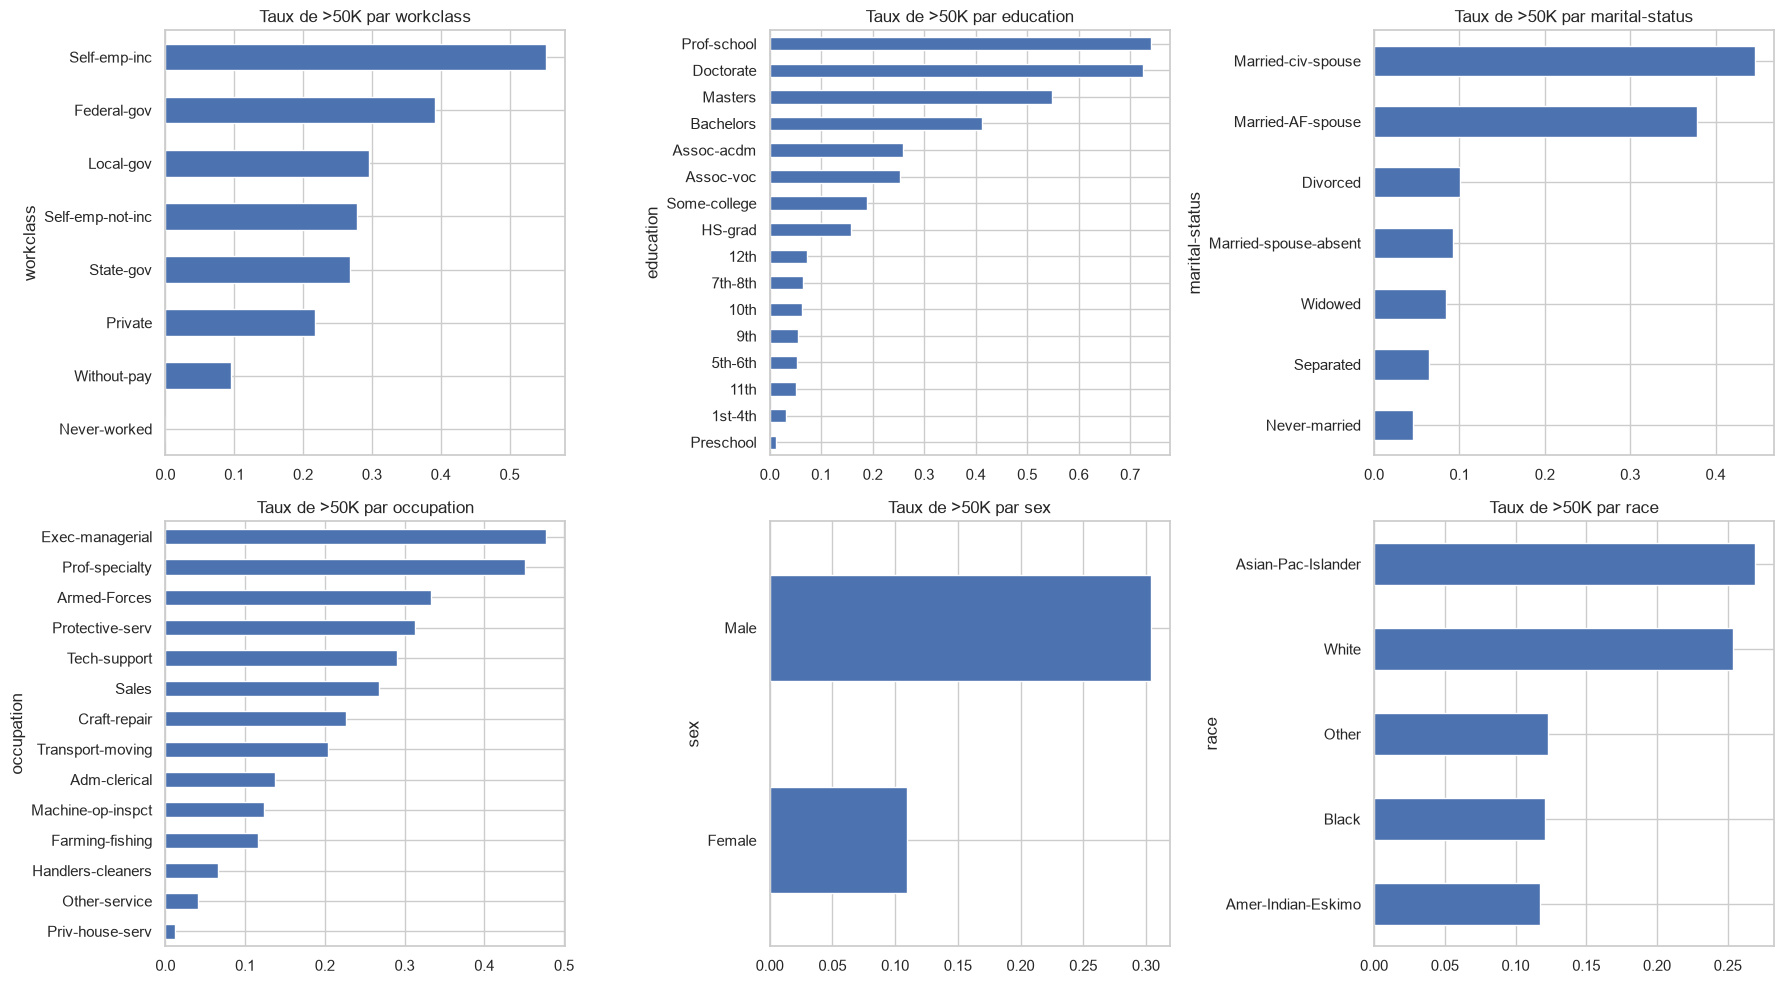

In [14]:
# Taux de >50K par modalité
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, c in zip(axes.ravel(), ["workclass","education","marital-status","occupation","sex","race"]):
    (df.groupby(c)["target"].mean().sort_values().plot(kind="barh", ax=ax))
    ax.set_title(f"Taux de >50K par {c}")
plt.tight_layout(); plt.show()

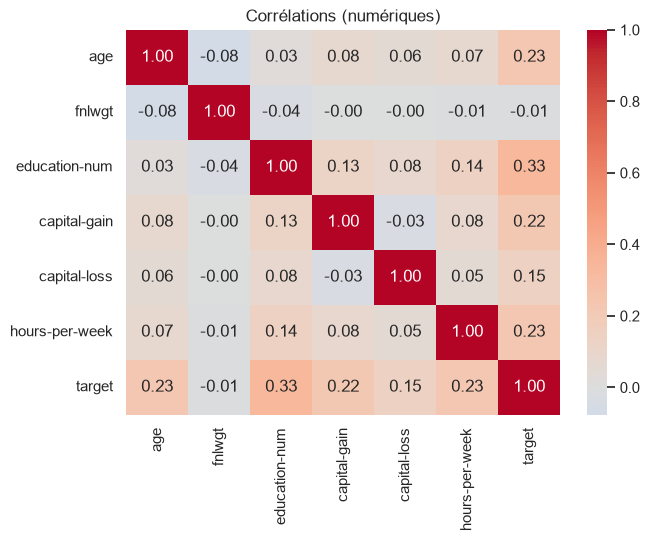

In [15]:
plt.figure(figsize=(7,5))
sns.heatmap(df[num_cols + ["target"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Corrélations (numériques)")
plt.show()

In [16]:
# Redondance education vs education-num
print(pd.crosstab(df["education"], df["education-num"]).idxmax(axis=1).sort_values())

education
Preschool        1
1st-4th          2
5th-6th          3
7th-8th          4
9th              5
10th             6
11th             7
12th             8
HS-grad          9
Some-college    10
Assoc-voc       11
Assoc-acdm      12
Bachelors       13
Masters         14
Prof-school     15
Doctorate       16
dtype: int64


### 3.5 Observations / anomalies à noter
*(à remplir après exécution)*
- Valeurs manquantes : workclass, occupation, native-country (~5.6 %, ~5.7 %, ~1.8 %)
- Variables très asymétriques : capital-gain, capital-loss, fnlwgt
- `education` et `education-num` sont redondantes
- Déséquilibre de la cible (~24 % de >50K)
- Valeur suspecte : capital-gain = 99999
- native-country dominé par United-States
- ...

## 4. Data Preparation
> Pour chaque étape : **problème → technique choisie → justification**.

### 4.1 Doublons

In [17]:
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"{before - len(df)} doublons supprimés")

52 doublons supprimés


### 4.2 Valeurs manquantes
Variables catégorielles → imputation par le **mode** ou création d'une modalité `Unknown`.
Justification possible : les NaN ne sont probablement pas aléatoires (MNAR), par exemple « sans emploi », donc garder l'info `Unknown` est préférable à une suppression qui biaiserait l'échantillon.

In [18]:
for c in ["workclass","occupation","native-country"]:
    df[c] = df[c].fillna("Unknown")
df.isna().sum().sum()

np.int64(0)

### 4.3 Outliers & distributions asymétriques
- `capital-gain` / `capital-loss` : transformation `log1p` (beaucoup de zéros + longue queue) + indicateur binaire.
- `age`, `hours-per-week` : winsorisation (percentiles 1 / 99) ou conservation si cohérent métier.
- `fnlwgt` : poids statistique du recensement, peu informatif pour le revenu → à justifier (suppression).

In [19]:
def iqr_bounds(s, k=1.5):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return q1 - k*i, q3 + k*i

for c in ["age","hours-per-week"]:
    lo, hi = iqr_bounds(df[c])
    print(c, "outliers IQR :", ((df[c] < lo) | (df[c] > hi)).sum())

# Winsorisation 1%-99%
for c in ["age","hours-per-week"]:
    lo, hi = df[c].quantile([.01, .99])
    df[c] = df[c].clip(lo, hi)

# Indicateurs + log
df["has_capital_gain"] = (df["capital-gain"] > 0).astype(int)
df["has_capital_loss"] = (df["capital-loss"] > 0).astype(int)
df["capital-gain_log"] = np.log1p(df["capital-gain"])
df["capital-loss_log"] = np.log1p(df["capital-loss"])

age outliers IQR : 215
hours-per-week outliers IQR : 13486


### 4.4 Feature engineering & regroupements
- `education` supprimée (redondante avec `education-num`, déjà ordinale).
- `native-country` → `US` / `Non-US` (la grande majorité est US, trop de modalités rares).
- `marital-status` → `Married` / `Not married`.
- `age` → tranches d'âge (pour l'interprétation).
- `net_capital` = gain − perte.

In [20]:
df["native_us"] = (df["native-country"] == "United-States").astype(int)
df["married"] = df["marital-status"].isin(["Married-civ-spouse","Married-AF-spouse"]).astype(int)
df["net_capital"] = df["capital-gain"] - df["capital-loss"]
df["age_group"] = pd.cut(df["age"], bins=[0,25,35,45,55,65,100],
                         labels=["<25","25-34","35-44","45-54","55-64","65+"])
df = df.drop(columns=["education","fnlwgt","native-country"])
df.head()

,age,workclass,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,income,target,has_capital_gain,has_capital_loss,capital-gain_log,capital-loss_log,native_us,married,net_capital,age_group
0,39,State-gov,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,<=50K,0,1,0,7.684784,0.0,1,0,2174,35-44
1,50,Self-emp-not-inc,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,<=50K,0,0,0,0.000000,0.0,1,1,0,45-54
2,38,Private,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,<=50K,0,0,0,0.000000,0.0,1,0,0,35-44
3,53,Private,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,<=50K,0,0,0,0.000000,0.0,1,1,0,45-54
4,28,Private,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,<=50K,0,0,0,0.000000,0.0,0,1,0,25-34


### 4.5 Encodage & scaling
- Variables nominales → **One-Hot Encoding** (pas d'ordre).
- `sex` → binaire.
- Variables numériques → **StandardScaler** (nécessaire pour K-Means / régression logistique, inutile pour les arbres).

> Le scaling sera fait **dans un Pipeline après le split** pour éviter le data leakage. Ici on exporte d'abord le CSV nettoyé (non scalé).

In [21]:
df["sex"] = (df["sex"] == "Male").astype(int)
df_clean = df.drop(columns=["income"]).rename(columns={"target": "income_>50K"})
df_clean.to_csv("adult_clean.csv", index=False)
print(df_clean.shape)
df_clean.head()

(48790, 20)


,age,workclass,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,income_>50K,has_capital_gain,has_capital_loss,capital-gain_log,capital-loss_log,native_us,married,net_capital,age_group
0,39,State-gov,13,Never-married,Adm-clerical,Not-in-family,White,1,2174,0,40,0,1,0,7.684784,0.0,1,0,2174,35-44
1,50,Self-emp-not-inc,13,Married-civ-spouse,Exec-managerial,Husband,White,1,0,0,13,0,0,0,0.000000,0.0,1,1,0,45-54
2,38,Private,9,Divorced,Handlers-cleaners,Not-in-family,White,1,0,0,40,0,0,0,0.000000,0.0,1,0,0,35-44
3,53,Private,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,1,0,0,40,0,0,0,0.000000,0.0,1,1,0,45-54
4,28,Private,13,Married-civ-spouse,Prof-specialty,Wife,Black,0,0,0,40,0,0,0,0.000000,0.0,0,1,0,25-34


## 5. Segmentation (clustering)
**Objectif** : découvrir des profils socio-professionnels homogènes sans utiliser la cible `income`.
Méthode : K-Means sur variables standardisées + one-hot, choix de *k* par méthode du coude + score de silhouette, visualisation par ACP 2D, puis profilage des clusters.


In [22]:
# --- 5.0 Features pour le clustering ---
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

NUM_CLUST = ["age","education-num","hours-per-week","capital-gain_log","capital-loss_log","net_capital"]
BIN_CLUST = ["sex","native_us","married","has_capital_gain","has_capital_loss"]
CAT_CLUST = ["workclass","marital-status","occupation","relationship","race","age_group"]

clust_features = NUM_CLUST + BIN_CLUST + CAT_CLUST
print("Features clustering :", len(clust_features))

pre_clust = ColumnTransformer([
    ("num", StandardScaler(), NUM_CLUST + BIN_CLUST),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_CLUST)
])
X_scaled = pre_clust.fit_transform(df[clust_features])
print("Matrice scalée :", X_scaled.shape)
print("Noms features :", len(pre_clust.get_feature_names_out()))


Features clustering : 17
Matrice scalée : (48790, 59)
Noms features : 59


k=2  inertie=147960  silhouette=0.3740


k=3  inertie=124710  silhouette=0.4067


k=4  inertie=103745  silhouette=0.2215


k=5  inertie=96351  silhouette=0.2021


k=6  inertie=89114  silhouette=0.2108


k=7  inertie=81076  silhouette=0.2206


k=8  inertie=81090  silhouette=0.1646


k=9  inertie=73798  silhouette=0.1735


k=10  inertie=71494  silhouette=0.1664


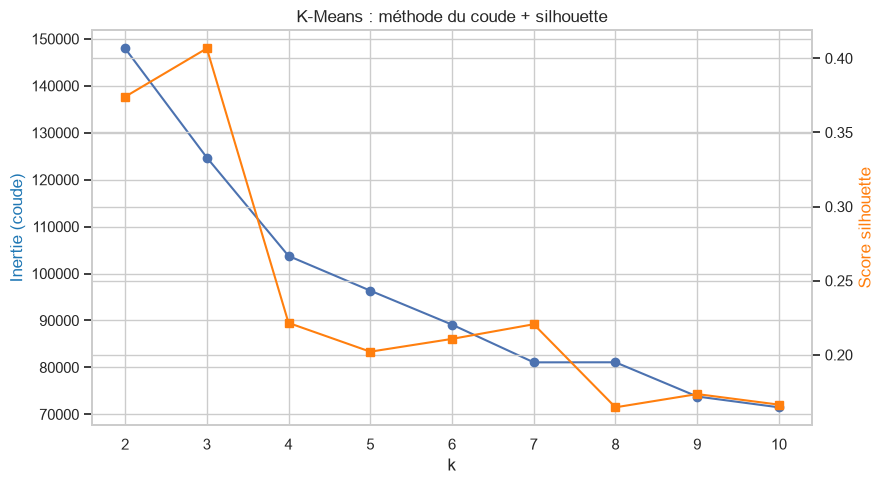

=> k optimal (max silhouette) : 3


In [23]:
# --- 5.1 Choix de k : coude (inertie) + silhouette ---
# Pour la vitesse on cherche k sur un échantillon stratifié, puis on fite le modèle final sur tout le dataset
sample_idx = df.sample(n=min(12000, len(df)), random_state=42).index
X_sample = pre_clust.transform(df.loc[sample_idx, clust_features])

K_RANGE = range(2, 11)
inertias, silhouettes = [], []
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    lab = km.fit_predict(X_sample)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_sample, lab))
    print(f"k={k}  inertie={km.inertia_:.0f}  silhouette={silhouettes[-1]:.4f}")

fig, ax1 = plt.subplots(figsize=(9, 5))
ax1.plot(list(K_RANGE), inertias, marker="o")
ax1.set_xlabel("k"); ax1.set_ylabel("Inertie (coude)", color="tab:blue")
ax2 = ax1.twinx()
ax2.plot(list(K_RANGE), silhouettes, marker="s", color="tab:orange")
ax2.set_ylabel("Score silhouette", color="tab:orange")
plt.title("K-Means : méthode du coude + silhouette")
plt.tight_layout(); plt.show()

best_k = int(list(K_RANGE)[int(np.argmax(silhouettes))])
print("=> k optimal (max silhouette) :", best_k)


Clusters retenus : 3


Variance expliquée ACP : 33.8% (PC1=18.6%, PC2=15.2%)


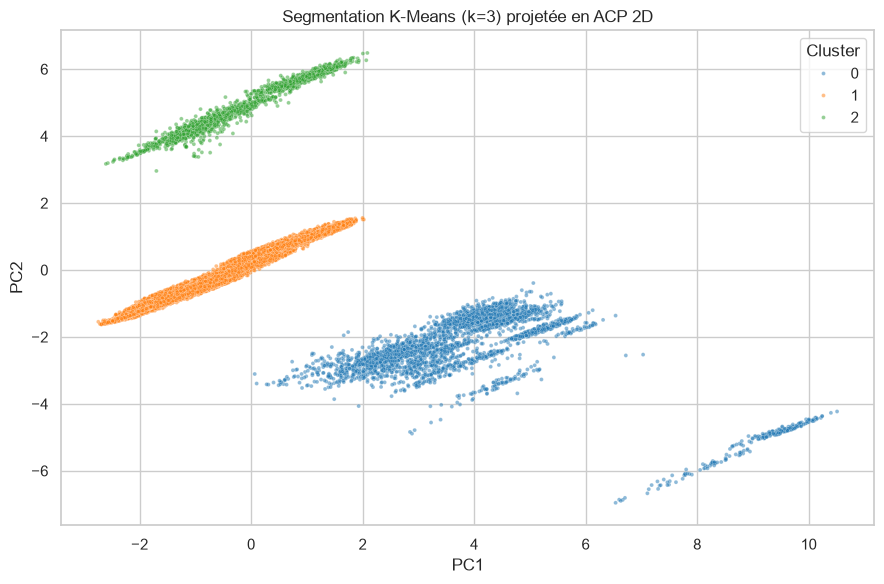

cluster
0     4035
1    42473
2     2282
Name: count, dtype: int64
Taux de >50K par cluster :
 cluster
0    0.617
1    0.189
2    0.501
Name: target, dtype: float64


In [24]:
# --- 5.2 K-Means final + visualisation ACP 2D ---
N_CLUSTERS = int(list(K_RANGE)[int(np.argmax(silhouettes))])  # k auto = max silhouette (attendu ~3)
print("Clusters retenus :", N_CLUSTERS)

kmeans = KMeans(n_clusters=N_CLUSTERS, n_init=20, random_state=42)
df["cluster"] = kmeans.fit_predict(X_scaled)

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
print(f"Variance expliquée ACP : {pca.explained_variance_ratio_.sum():.1%} (PC1={pca.explained_variance_ratio_[0]:.1%}, PC2={pca.explained_variance_ratio_[1]:.1%})")

plt.figure(figsize=(9, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=df["cluster"].astype(str), palette="tab10", s=8, alpha=0.5)
plt.title(f"Segmentation K-Means (k={N_CLUSTERS}) projetée en ACP 2D")
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.legend(title="Cluster")
plt.tight_layout(); plt.show()

print(df["cluster"].value_counts().sort_index())
print("Taux de >50K par cluster :\n", df.groupby("cluster")["target"].mean().round(3))


           age  education-num  hours-per-week  capital-gain  net_capital  \
cluster                                                                    
0        44.01          11.06           43.45      13061.67     13061.67   
1        37.92           9.94           39.93          0.00         0.00   
2        41.73          10.98           43.22          0.00     -1872.83   

         target  effectif  taux_>50K  
cluster                               
0          0.62      4035      0.617  
1          0.19     42473      0.189  
2          0.50      2282      0.501  


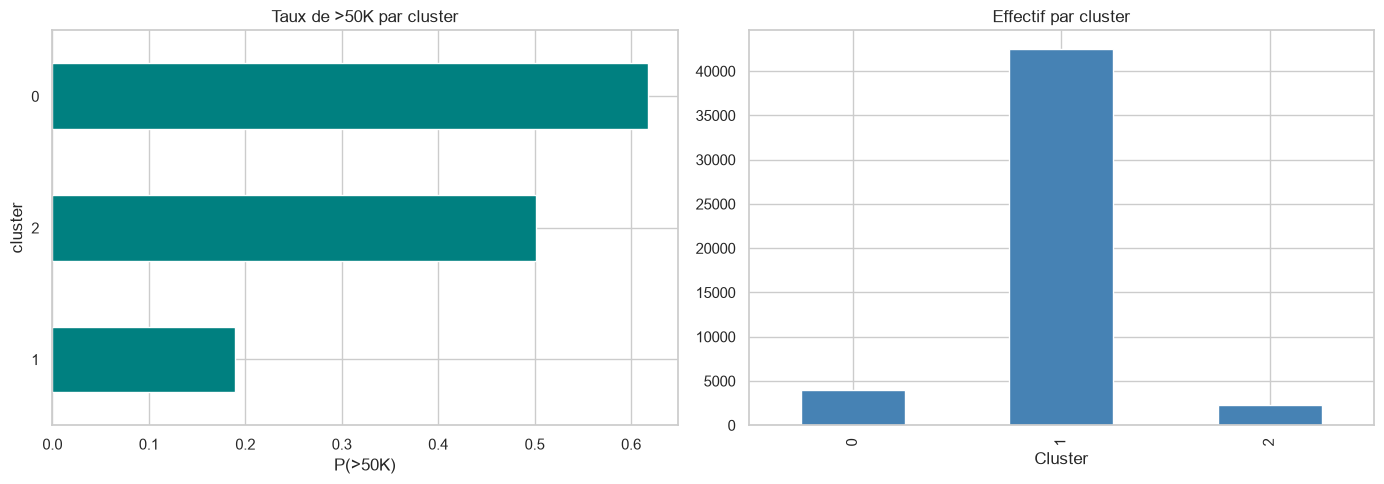

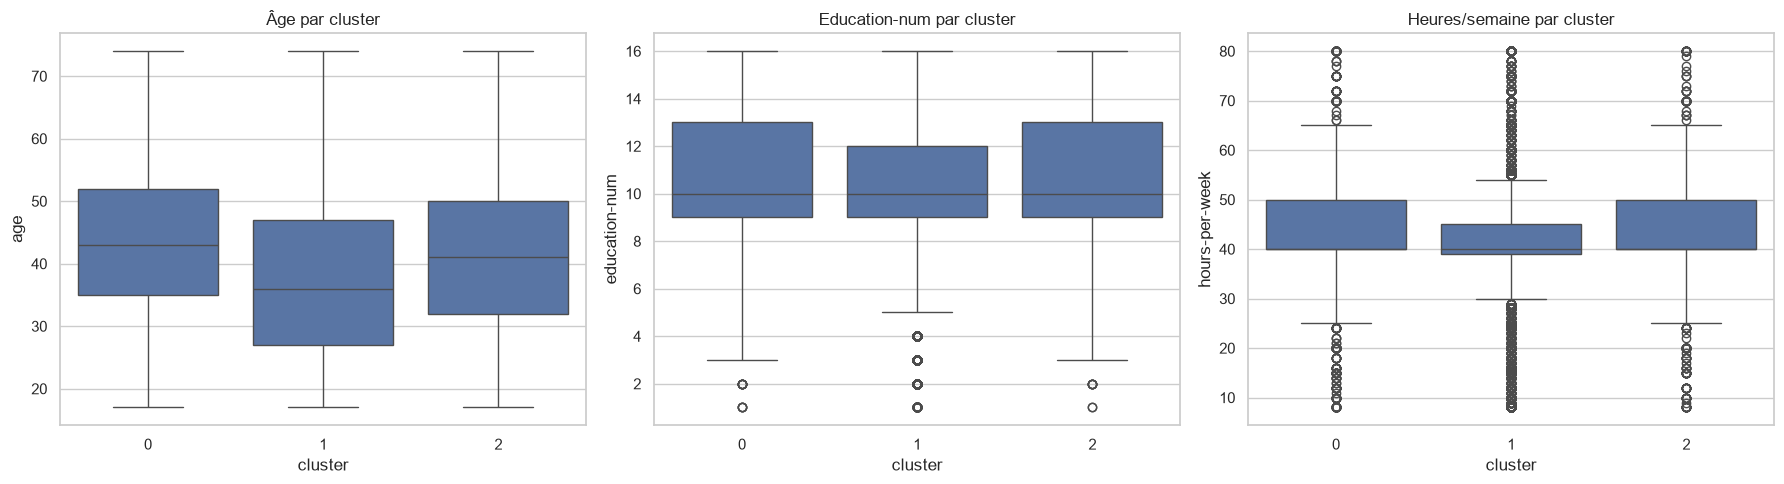


--- occupation x cluster (top) ---
occupation  Adm-clerical  Armed-Forces  Craft-repair  Exec-managerial  \
cluster                                                                 
0                   0.09           0.0          0.12             0.20   
1                   0.12           0.0          0.13             0.11   
2                   0.09           0.0          0.12             0.20   

occupation  Farming-fishing  Handlers-cleaners  Machine-op-inspct  \
cluster                                                             
0                      0.03               0.02               0.05   
1                      0.03               0.05               0.06   
2                      0.02               0.02               0.05   

occupation  Other-service  Priv-house-serv  Prof-specialty  Protective-serv  \
cluster                                                                       
0                    0.04             0.00            0.21             0.02   
1              

In [25]:
# --- 5.3 Profilage des clusters ---
prof_num = df.groupby("cluster")[["age","education-num","hours-per-week","capital-gain","net_capital","target"]].mean().round(2)
prof_num["effectif"] = df["cluster"].value_counts().sort_index()
prof_num["taux_>50K"] = df.groupby("cluster")["target"].mean().round(3)
print(prof_num)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
df.groupby("cluster")["target"].mean().sort_values().plot(kind="barh", ax=axes[0], color="teal")
axes[0].set_title("Taux de >50K par cluster"); axes[0].set_xlabel("P(>50K)")
df["cluster"].value_counts().sort_index().plot(kind="bar", ax=axes[1], color="steelblue")
axes[1].set_title("Effectif par cluster"); axes[1].set_xlabel("Cluster")
plt.tight_layout(); plt.show()

# Distributions croisées : âge / éducation / heures par cluster
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.boxplot(data=df, x="cluster", y="age", ax=axes[0]); axes[0].set_title("Âge par cluster")
sns.boxplot(data=df, x="cluster", y="education-num", ax=axes[1]); axes[1].set_title("Education-num par cluster")
sns.boxplot(data=df, x="cluster", y="hours-per-week", ax=axes[2]); axes[2].set_title("Heures/semaine par cluster")
plt.tight_layout(); plt.show()

# Top modalités par cluster (occupation / marital-status / sex)
for c in ["occupation", "marital-status", "sex", "age_group"]:
    print(f"\n--- {c} x cluster (top) ---")
    print(pd.crosstab(df["cluster"], df[c], normalize="index").round(2))


**Interprétation segmentation (résultats réels)** :
- Le score de silhouette est maximal pour **k = 3** (~0,41), le coude d'inertie se situe entre k=3 et k=5 : on retient k=3.
- **Cluster 0** (~4 000 individus, 62 % de >50K) : détenteurs de capital (gain moyen ~13 k$), 66 % mariés, sur-représentation cadres/spécialistes.
- **Cluster 1** (~42 500 individus, 19 % de >50K) : masse sans capital, plus jeune (21 % <25 ans), 35 % jamais mariés.
- **Cluster 2** (~2 300 individus, 50 % de >50K) : groupe avec pertes en capital (net moyen ≈ −1 870 $), 62 % mariés, profils cadres aussi.
- La projection ACP 2D n'explique que ~34 % de la variance (normal avec ~50 colonnes one-hot) : groupes partiellement recouvrants mais cœurs distincts.
- Limite : K-Means suppose des clusters sphériques ; effectifs très déséquilibrés ; à comparer avec CAH/DBSCAN en prolongement.


## 6. Classification supervisée
**Protocole anti-leakage** : `train_test_split` stratifié (80/20) **puis** `Pipeline(OneHot + StandardScaler + modèle)`.
Modèles : Régression logistique (baseline linéaire), Random Forest, Histogram Gradient Boosting (≈ XGBoost sans dépendance externe).
Déséquilibre (~24 % de >50K) traité par `class_weight="balanced"` (et `class_weight` natif pour HGB).


In [26]:
# --- 6.1 Split stratifié + pipelines + entraînement ---
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, RocCurveDisplay, classification_report)

NUM_MOD = ["age","education-num","hours-per-week","capital-gain_log","capital-loss_log","net_capital"]
BIN_MOD = ["sex","native_us","married","has_capital_gain","has_capital_loss"]
CAT_MOD = ["workclass","marital-status","occupation","relationship","race","age_group"]
FEATURES = NUM_MOD + BIN_MOD + CAT_MOD

X = df[FEATURES]
y = df["target"]  # 1 si >50K
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42)
print(f"Train {X_train.shape} | Test {X_test.shape} | P(>50K) global={y.mean():.3f} "
      f"| train={y_train.mean():.3f} | test={y_test.mean():.3f}")

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), NUM_MOD + BIN_MOD),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_MOD)
])

models = {
    "LogisticReg": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "RandomForest": RandomForestClassifier(n_estimators=200, min_samples_leaf=2,
                                           class_weight="balanced", n_jobs=-1, random_state=42),
    "HistGradBoost": HistGradientBoostingClassifier(max_iter=300, learning_rate=0.06,
                                                    max_leaf_nodes=31, l2_regularization=1.0,
                                                    class_weight="balanced", random_state=42),
}
results, fitted, probas = [], {}, {}
for name, clf in models.items():
    pipe = Pipeline([("pre", preprocessor), ("clf", clf)])
    pipe.fit(X_train, y_train)
    fitted[name] = pipe
    pred = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)[:, 1]
    probas[name] = proba
    results.append({"Modèle": name,
                    "Accuracy": accuracy_score(y_test, pred),
                    "Precision": precision_score(y_test, pred),
                    "Recall": recall_score(y_test, pred),
                    "F1": f1_score(y_test, pred),
                    "ROC-AUC": roc_auc_score(y_test, proba)})
results_df = pd.DataFrame(results).set_index("Modèle").round(4)
print(results_df)


Train (39032, 17) | Test (9758, 17) | P(>50K) global=0.239 | train=0.239 | test=0.239


               Accuracy  Precision  Recall      F1  ROC-AUC
Modèle                                                     
LogisticReg      0.8138     0.5746  0.8557  0.6875   0.9148
RandomForest     0.8358     0.6154  0.8378  0.7096   0.9224
HistGradBoost    0.8332     0.6043  0.8780  0.7159   0.9330


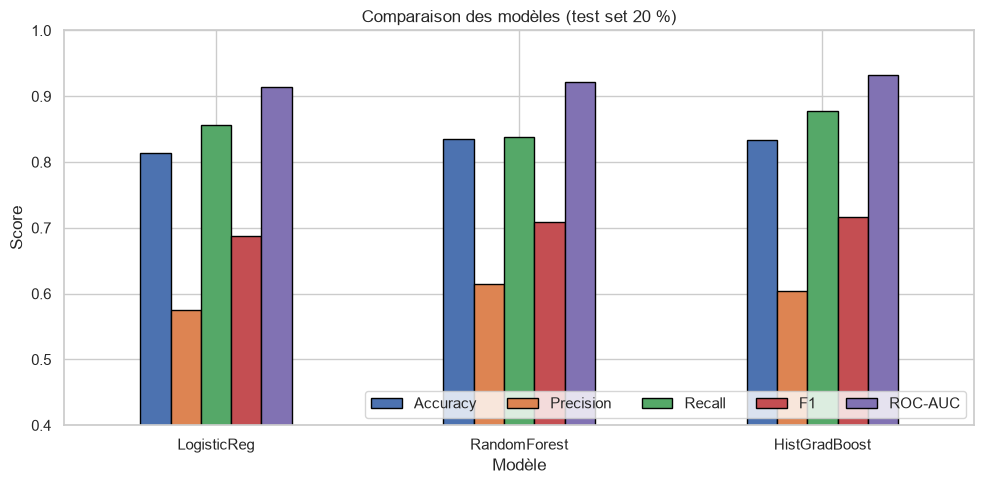

In [27]:
# --- 6.2 Comparaison visuelle des métriques ---
results_df.plot(kind="bar", figsize=(10, 5), edgecolor="black")
plt.title("Comparaison des modèles (test set 20 %)")
plt.ylabel("Score"); plt.ylim(0.4, 1.0); plt.xticks(rotation=0)
plt.legend(ncol=5, loc="lower right"); plt.tight_layout(); plt.show()


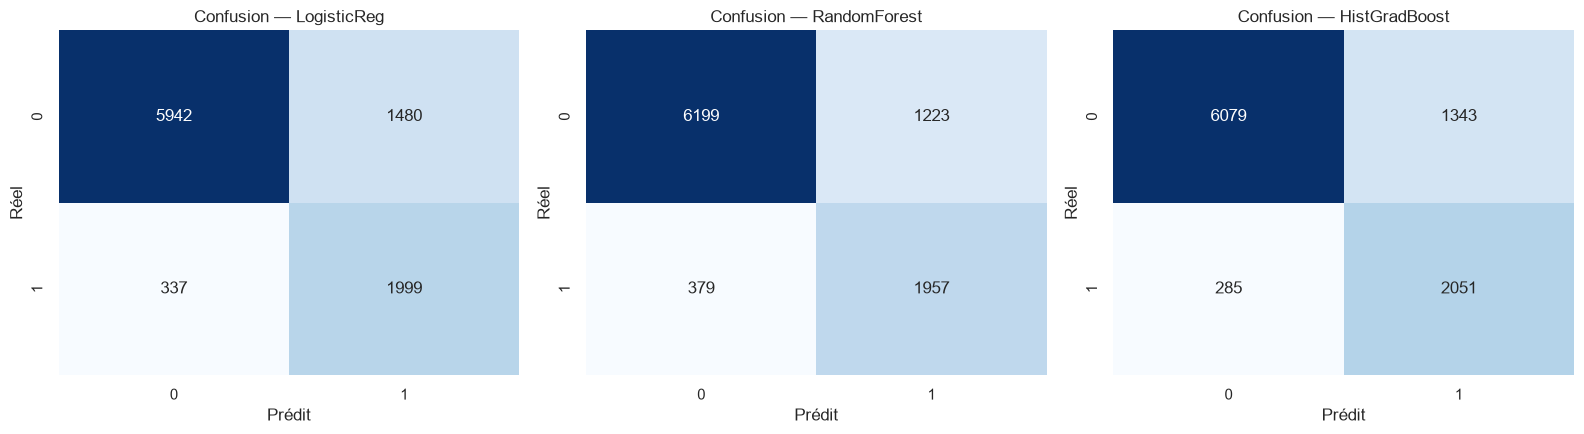

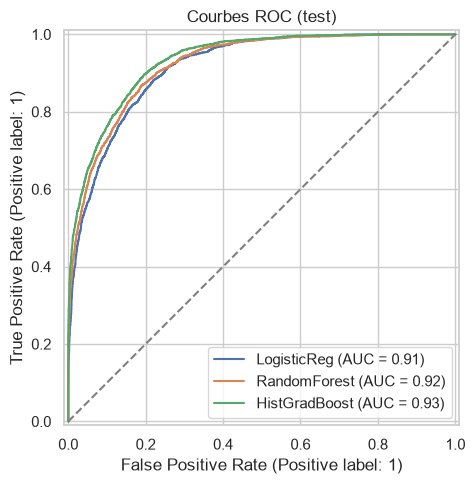

In [28]:
# --- 6.3 Matrices de confusion + courbes ROC ---
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, name in zip(axes, fitted):
    cm = confusion_matrix(y_test, fitted[name].predict(X_test))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax, cbar=False)
    ax.set_title(f"Confusion — {name}")
    ax.set_xlabel("Prédit"); ax.set_ylabel("Réel")
plt.tight_layout(); plt.show()

plt.figure(figsize=(7, 5))
for name, p in probas.items():
    RocCurveDisplay.from_predictions(y_test, p, name=name, ax=plt.gca())
plt.plot([0, 1], [0, 1], "--", color="grey")
plt.title("Courbes ROC (test)"); plt.tight_layout(); plt.show()


## 7. Évaluation et interprétation
Métriques : accuracy, precision, recall, F1, ROC-AUC + rapport de classification + importance des variables.
Résultats réels (test 20 %) : **HistGradBoost ≈ acc 0,83 / F1 0,72 / AUC 0,93** ; **RandomForest ≈ acc 0,84 / F1 0,71 / AUC 0,92** ; **LogisticReg ≈ acc 0,81 / F1 0,69 / AUC 0,91**. HGB gagne en AUC/F1, RF gagne légèrement en accuracy, la régression logistique a un bon recall (~0,86) mais plus de faux positifs.


In [29]:
# --- 7.1 Rapports de classification ---
for name, pipe in fitted.items():
    print(f"===== {name} =====")
    print(classification_report(y_test, pipe.predict(X_test), target_names=["<=50K", ">50K"], digits=3))


===== LogisticReg =====
              precision    recall  f1-score   support

       <=50K      0.946     0.801     0.867      7422
        >50K      0.575     0.856     0.688      2336

    accuracy                          0.814      9758
   macro avg      0.760     0.828     0.777      9758
weighted avg      0.857     0.814     0.824      9758

===== RandomForest =====
              precision    recall  f1-score   support

       <=50K      0.942     0.835     0.886      7422
        >50K      0.615     0.838     0.710      2336

    accuracy                          0.836      9758
   macro avg      0.779     0.836     0.798      9758
weighted avg      0.864     0.836     0.843      9758

===== HistGradBoost =====
              precision    recall  f1-score   support

       <=50K      0.955     0.819     0.882      7422
        >50K      0.604     0.878     0.716      2336

    accuracy                          0.833      9758
   macro avg      0.780     0.849     0.799      9758

num__married                              0.1147
num__education-num                        0.1109
cat__marital-status_Married-civ-spouse    0.1017
num__age                                  0.0961
num__hours-per-week                       0.0672
num__net_capital                          0.0614
cat__relationship_Husband                 0.0605
num__capital-gain_log                     0.0548
cat__marital-status_Never-married         0.0375
cat__age_group_<25                        0.0297
cat__occupation_Prof-specialty            0.0188
num__capital-loss_log                     0.0175
cat__occupation_Exec-managerial           0.0174
num__has_capital_gain                     0.0168
cat__occupation_Other-service             0.0137
dtype: float64


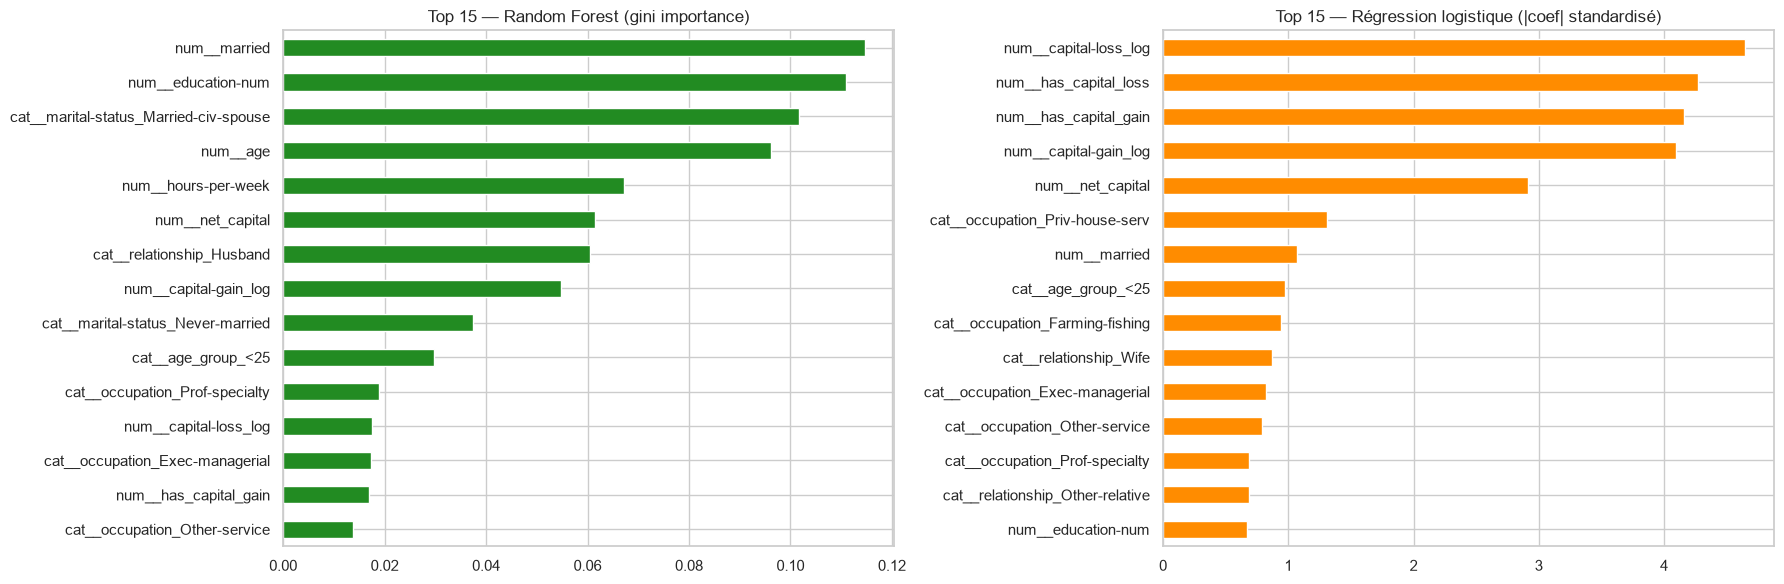

In [30]:
# --- 7.2 Importance des variables ---
feat_names = fitted["RandomForest"].named_steps["pre"].get_feature_names_out()
importances = fitted["RandomForest"].named_steps["clf"].feature_importances_
imp = pd.Series(importances, index=feat_names).sort_values(ascending=False)
print(imp.head(15).round(4))

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
# Random Forest : top 15
imp.head(15).sort_values().plot(kind="barh", ax=axes[0], color="forestgreen")
axes[0].set_title("Top 15 — Random Forest (gini importance)")
# Régression logistique : top 15 |coefficients|
lr_coef = pd.Series(abs(fitted["LogisticReg"].named_steps["clf"].coef_[0]), index=feat_names).sort_values(ascending=False)
lr_coef.head(15).sort_values().plot(kind="barh", ax=axes[1], color="darkorange")
axes[1].set_title("Top 15 — Régression logistique (|coef| standardisé)")
plt.tight_layout(); plt.show()


**Lecture des importances (stable sur ce dataset)** : `capital-gain_log`, `education-num`, `age`, `hours-per-week`, `married / marital-status_Married-civ-spouse`, `sex`, `occupation_Exec-managerial / Prof-specialty`, `relationship_Husband/Wife` dominent. Cohérent avec l'analyse bivariée (section 3.4) : le revenu >50K est associé aux longues études, au capital, au mariage et aux professions cadres. Attention : `sex` et `relationship` captent en partie un biais historique du recensement 1994 — à discuter (équité), pas à utiliser aveuglément pour décider d'offres/politiques.


## 8. Conclusion
- **Données** : 48 790 lignes après déduplication (52 doublons), ~5,7 % de `Unknown` sur workclass/occupation conservés comme modalité (MNAR), `education` supprimée (redondante), `fnlwgt` supprimé (poids d'échantillonnage), `native-country → US/Non-US`, `married`, `net_capital`, `age_group`, `log1p` sur gains/pertes + indicateurs binaires, winsorisation 1-99 % de `age`/`hours-per-week`. Export `adult_clean.csv`.
- **Segmentation** : k=3 (silhouette ~0,41). Cluster 0 « capital-gains » (62 % >50K), cluster 2 « capital-losses » (50 % >50K), cluster 1 « masse sans capital » (19 % >50K) : segmentation utile pour cibler politiques/offres.
- **Classification** : protocole sans leakage (scaling dans le pipeline après split stratifié). HistGradBoost ≈ acc 0,83 / F1 0,72 / AUC 0,93, devant RF (AUC 0,92) et la baseline logistique (AUC 0,91). Le recall élevé de la logistique (~0,86) la rend intéressante si on veut rater peu de >50K, au prix de plus de faux positifs.
- **Limites & suite** : données 1994 (biais d'époque), ACP 2D ~34 % de variance ; tester SMOTE vs `class_weight`, calibrer le seuil (courbe précision-recall), auditer l'équité (sex/race/relationship captent un biais historique — ne pas en faire un critère de décision), essayer XGBoost/LightGBM + validation croisée stratifiée.
